# Monte Carlo Pricing of European Options

This notebook prices European calls and puts by Monte Carlo simulation and compares the result
with the Black-Scholes closed-form price.

**Notation**

* $S_0$: initial price of the underlying
* $K$: strike price
* $\sigma$: volatility
* $r$: risk-free interest rate
* $q$: continuous dividend yield
* $T$: maturity of the option (in years)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(seed=42)  # fixed seed for reproducible results

## Monte Carlo estimator

Under the risk-neutral measure, the underlying follows a geometric Brownian motion:

$$
S_T = S_0 \exp\left(\left(r - q - \tfrac{\sigma^2}{2}\right)T + \sigma\sqrt{T}\,Z\right), \qquad Z \sim \mathcal{N}(0,1)
$$

A European payoff only depends on $S_T$, and $\ln S_T$ is exactly Gaussian, so $S_T$ can be sampled
in a single step with no discretisation error.

We simulate a large number of terminal prices, compute the payoff of each one, then take the
discounted average. By the law of large numbers this average converges to the option price, and by the
central limit theorem the error is of order $1/\sqrt{n}$, which gives a confidence interval.

In [2]:
def monte_carlo_pricer(S0, K, sigma, r, q, T, n_sims, option_type="call", rng=rng):
    # Terminal prices of the underlying (exact simulation of the GBM)
    Z = rng.standard_normal(n_sims)
    ST = S0 * np.exp((r - q - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

    # Payoff of each simulated path
    if option_type == "call":
        payoff = np.maximum(ST - K, 0.0)
    elif option_type == "put":
        payoff = np.maximum(K - ST, 0.0)
    else:
        raise ValueError("option_type must be 'call' or 'put'")

    # Discounted payoffs: their mean is the price estimate
    discounted = np.exp(-r * T) * payoff
    price = discounted.mean()
    std_error = discounted.std(ddof=1) / np.sqrt(n_sims)

    return price, std_error

## Black-Scholes price

Closed-form price of a European option on an underlying paying a continuous dividend yield $q$:

$$
C = S_0 e^{-qT} N(d_1) - K e^{-rT} N(d_2), \qquad
P = K e^{-rT} N(-d_2) - S_0 e^{-qT} N(-d_1)
$$

$$
d_1 = \frac{\ln(S_0/K) + (r - q + \sigma^2/2)\,T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}
$$

In [3]:
def black_scholes_price(S0, K, sigma, r, q, T, option_type="call"):
    d1 = (np.log(S0 / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    if option_type == "call":
        return S0 * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    elif option_type == "put":
        return K * np.exp(-r * T) * norm.cdf(-d2) - S0 * np.exp(-q * T) * norm.cdf(-d1)
    raise ValueError("option_type must be 'call' or 'put'")

## Comparison of the two prices

In [4]:
# Parameters
S0 = 130
K = 135
sigma = 0.30
r = 0.05
q = 0.02
T = 0.5
n_sims = 100_000

for option_type in ["call", "put"]:
    mc_price, se = monte_carlo_pricer(S0, K, sigma, r, q, T, n_sims, option_type)
    bs_price = black_scholes_price(S0, K, sigma, r, q, T, option_type)
    rel_diff = abs(mc_price - bs_price) / bs_price * 100

    print(f"{option_type.upper()}")
    print(f"  Monte Carlo price   : {mc_price:.4f}  (95% CI: [{mc_price - 1.96*se:.4f}, {mc_price + 1.96*se:.4f}])")
    print(f"  Black-Scholes price : {bs_price:.4f}")
    print(f"  Relative difference : {rel_diff:.2f}%\n")

CALL
  Monte Carlo price   : 9.5707  (95% CI: [9.4639, 9.6774])
  Black-Scholes price : 9.5796
  Relative difference : 0.09%

PUT
  Monte Carlo price   : 12.5194  (95% CI: [12.4257, 12.6132])
  Black-Scholes price : 12.5399
  Relative difference : 0.16%



The Black-Scholes price falls inside the 95% confidence interval of the Monte Carlo estimate.

## Convergence of the estimator

The plot below shows the Monte Carlo price and its 95% confidence interval as the number of
simulations grows. The interval narrows at rate $1/\sqrt{n}$: dividing the error by 10 requires
100 times more simulations.

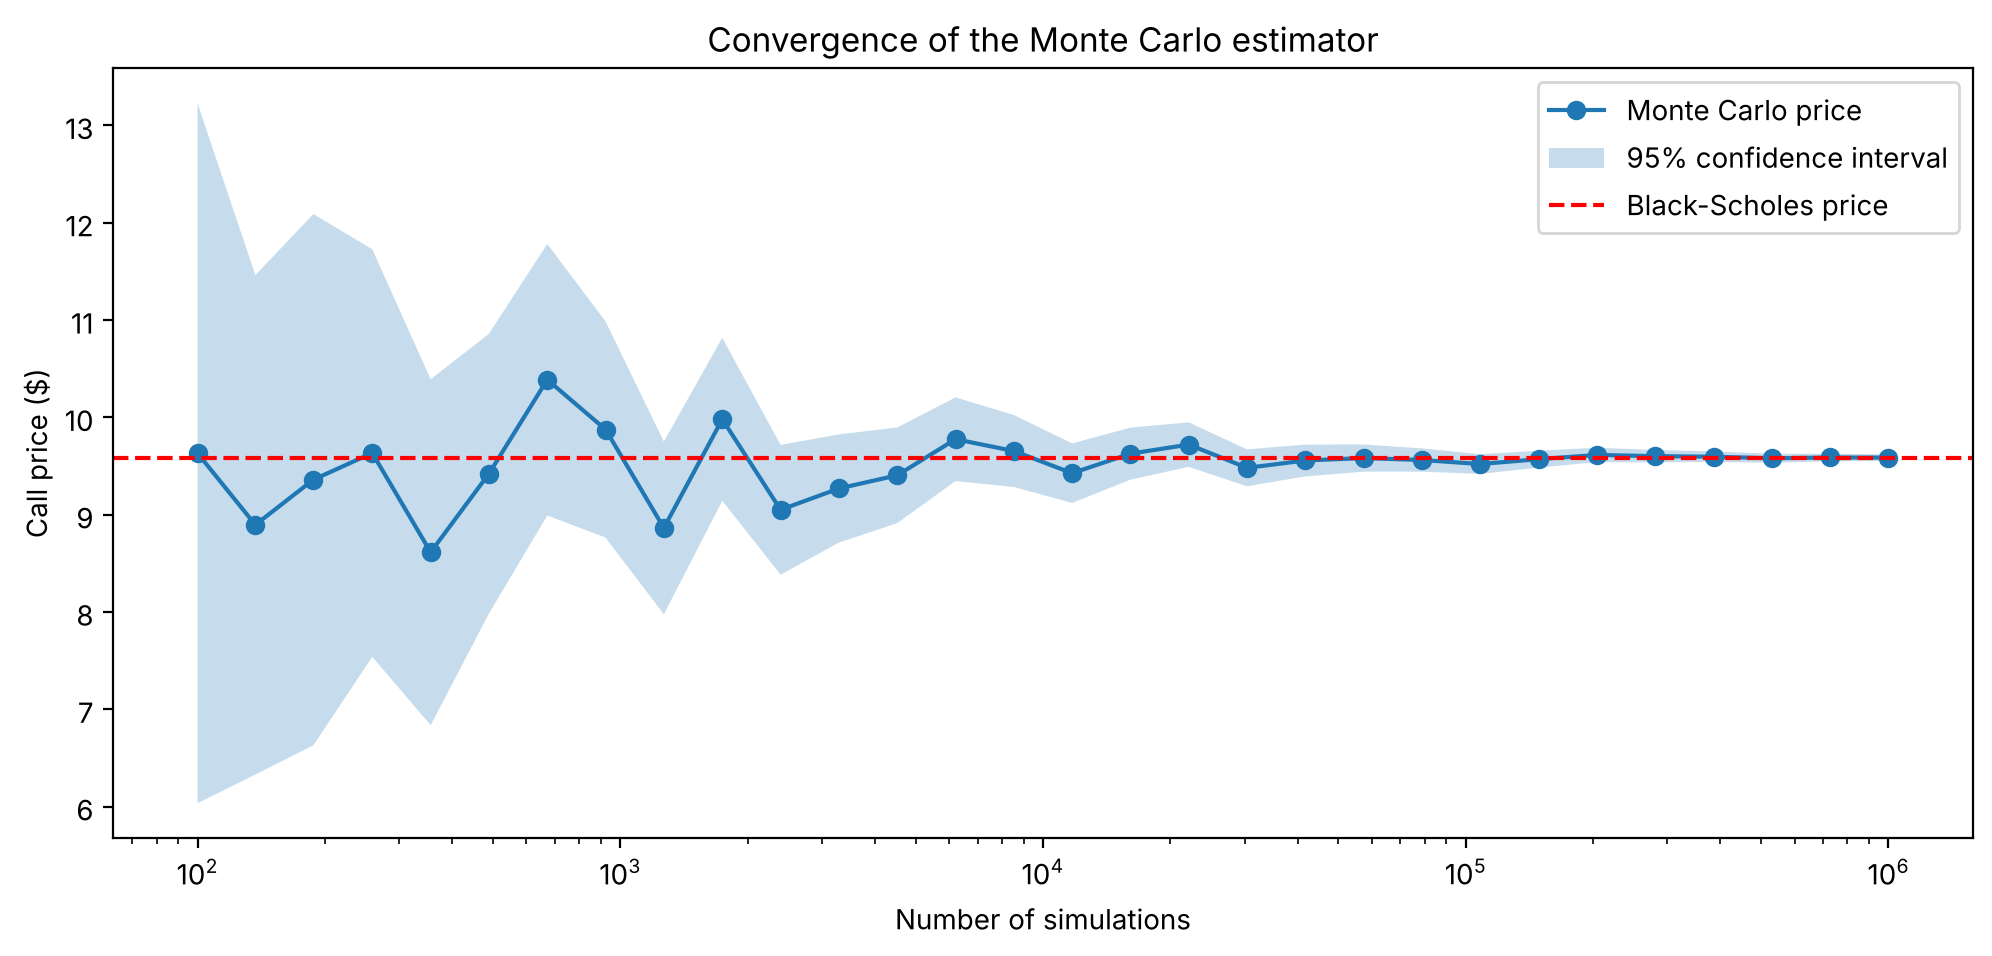

In [5]:
sims_grid = np.unique(np.logspace(2, 6, 30).astype(int))
prices, errors = [], []
for n in sims_grid:
    p, se = monte_carlo_pricer(S0, K, sigma, r, q, T, n, "call")
    prices.append(p)
    errors.append(se)
prices, errors = np.array(prices), np.array(errors)
bs_call = black_scholes_price(S0, K, sigma, r, q, T, "call")

plt.figure(figsize=(12, 5))
plt.semilogx(sims_grid, prices, "o-", label="Monte Carlo price")
plt.fill_between(sims_grid, prices - 1.96 * errors, prices + 1.96 * errors, alpha=0.25, label="95% confidence interval")
plt.axhline(bs_call, color="r", linestyle="--", label="Black-Scholes price")
plt.xlabel("Number of simulations")
plt.ylabel("Call price ($)")
plt.title("Convergence of the Monte Carlo estimator")
plt.legend()
plt.show()